# FreshBasket Loyalty - Data quality & EDA
This notebook audits the three source tables, builds the leakage-safe modelling dataset and explores the churn signal. All numbers come from the same `src/` modules used by `run_pipeline.py`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
import pandas as pd, numpy as np
from IPython.display import Image, display
from config import *
from data_prep import load_raw, clean
from features import build_features
pd.set_option('display.width', 200, 'display.max_columns', 40, 'display.max_colwidth', 90)
raw = load_raw()
for k, v in raw.items(): print(k, v.shape)

profile (2608, 10)
activity (28073, 12)
label (2605, 6)


## 1. Data-quality audit
Issues are detected and fixed in `data_prep.clean`; every fix is counted.

In [2]:
p, a, l, audit = clean(raw, save_audit=False)
audit

,table,issue,rows_affected,action
0,profile,exact duplicate rows,8,dropped
1,label,exact duplicate rows,5,dropped
2,activity,exact duplicate rows,58,dropped
3,activity,same customer-month with conflicting values,2,kept first
4,profile,inconsistent casing/whitespace in MEMBERSHIP_TIER (12 variants -> 3),9,strip + title-case
5,profile,inconsistent casing/whitespace in CITY (40 variants -> 10),30,strip + title-case
6,profile,missing AGE,78,median/'Unknown' imputation + missing flag
7,profile,missing GENDER,52,median/'Unknown' imputation + missing flag
8,profile,missing HOME_STORE_PRICE_TIER,130,median/'Unknown' imputation + missing flag
9,activity,negative TOTAL_SPEND,23,rebuilt as AVG_BASKET_VALUE x TRANSACTIONS


**Key judgement calls**
* Rows only exist for months a member was *on file*; months after a member's last row are treated as **zero activity** (not missing) while gaps in the middle of a history stay `NaN` and are counted as a feature.
* `TOTAL_SPEND` errors (negative, zero-with-transactions, 13 extreme outliers) are rebuilt from `AVG_BASKET_VALUE x TRANSACTIONS`.
* `LAST_PURCHASE_DATE`, `MONTHS_OBSERVED`, `INSUFFICIENT_HISTORY_FLAG` in the label table are computed with the label window, so they are **excluded** (leakage).

In [3]:
F = build_features(p, a, FEATURE_CUTOFF).join(l.set_index('CUSTOMER_ID').CHURNED)
print('members', len(p), '| eligible (bought on/before Mar-24):', int(F.eligible.sum()))
E = F[F.eligible == 1].copy(); E['y'] = E.CHURNED.astype(int)
print('churn rate (eligible): %.1f%%' % (100 * E.y.mean()))
print('official label vs label re-derived from activity rows - disagreements:', int((E.CHURNED != E.churn_derived).sum()))
E.head()

members 2600 | eligible (bought on/before Mar-24): 2368
churn rate (eligible): 34.3%
official label vs label re-derived from activity rows - disagreements: 4


,recency_months,txn_l3,spend_l3,txn_l6,spend_l6,txn_l12,spend_l12,active_months_l3,active_months_l6,txn_ratio_l3_prev3,spend_ratio_l3_prev3,txn_slope_l6,spend_slope_l6,basket_l3,basket_change,categories_l3,promo_pct_l3,promo_pct_l6,promo_change,months_with_purchase,...,ticket_change,months_since_ticket,tenure_months,history_months,short_history_flag,missing_months,age,age_missing,gender,city,membership_tier,marketing_opt_in,preferred_category,home_price_tier,signup_date,avg_monthly_spend_l6,eligible,churn_derived,CHURNED,y
CUSTOMER_ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
500001,0.0,21.0,438.28,28.0,601.30,57.0,1279.71,3,5,2.750000,2.678210,1.300000,22.855000,20.870476,0.971850,3.666667,0.198571,0.250714,-0.052143,14.0,...,-1.0,3.0,19.4,15,0,1,36.0,0,F,Madison,Silver,1,Frozen Foods,Value,2022-08-17,100.216667,1,0,0,0
500002,0.0,12.0,357.11,31.0,988.54,53.0,1792.40,3,6,0.650000,0.566244,-0.771429,-27.942857,29.759167,0.933229,1.000000,0.248333,0.398065,-0.149731,9.0,...,0.0,8.0,9.2,10,0,1,37.0,0,F,Spokane,Silver,0,Beverages,Mainstream,2023-06-24,164.756667,1,0,0,0
500003,0.0,14.0,489.49,24.0,850.42,56.0,1815.80,3,6,1.363636,1.355207,0.742857,25.456000,34.963571,0.986719,2.000000,0.515714,0.444583,0.071131,14.0,...,2.0,1.0,36.0,15,0,1,53.0,0,Unknown,Tulsa,Gold,0,Frozen Foods,Mainstream,2021-03-31,141.736667,1,0,0,0
500004,0.0,16.0,367.99,25.0,589.12,59.0,1406.25,3,5,1.700000,1.661144,0.058140,0.710930,22.999375,0.976006,3.666667,0.144375,0.194400,-0.050025,14.0,...,0.0,9.0,32.8,15,0,1,52.0,0,F,Spokane,Gold,1,Snacks,Upscale,2021-07-08,98.186667,1,0,0,0
500006,1.0,4.0,116.51,14.0,478.57,29.0,979.58,2,5,0.454545,0.323666,-0.285714,-12.495714,29.127500,0.852091,1.000000,0.262500,0.394286,-0.131786,14.0,...,1.0,1.0,18.5,15,0,0,44.0,0,F,Nashville,Silver,0,Snacks,Upscale,2022-09-14,79.761667,1,0,0,0


## 2. Leakage-safe design
Features use activity up to **Mar-2024** only; the label window is Apr-Jun 2024. Members who never purchased before April cannot 'churn' by definition and are excluded.

In [4]:
from eda import run_eda
segtab, summ = run_eda(E, a, audit)
summ

{'eligible': 2368,
 'churn_rate': np.float64(0.3433277027027027),
 'active_base': 1653,
 'active_base_churn': np.float64(0.06896551724137931),
 'lapsed2plus': 715,
 'lapsed2plus_churn': np.float64(0.9776223776223776)}

### 2.1 Data-quality summary

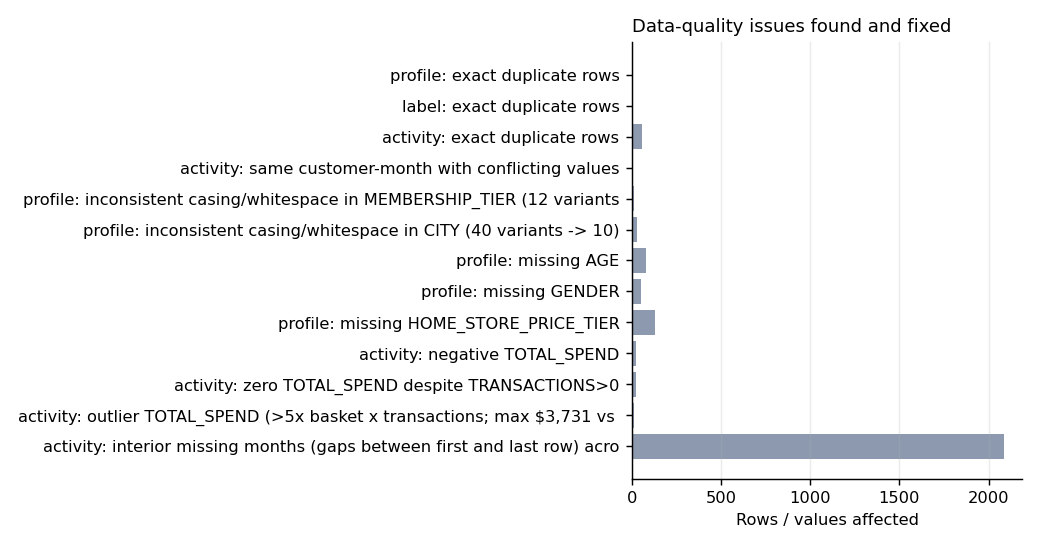

In [5]:
display(Image(str(FIG / 'eda_01_data_quality.png')))

### 2.2 Recency dominates
A member who has not bought for 3+ months is almost certainly churned; the real early-warning problem is the **active base** (bought in Feb/Mar-24).

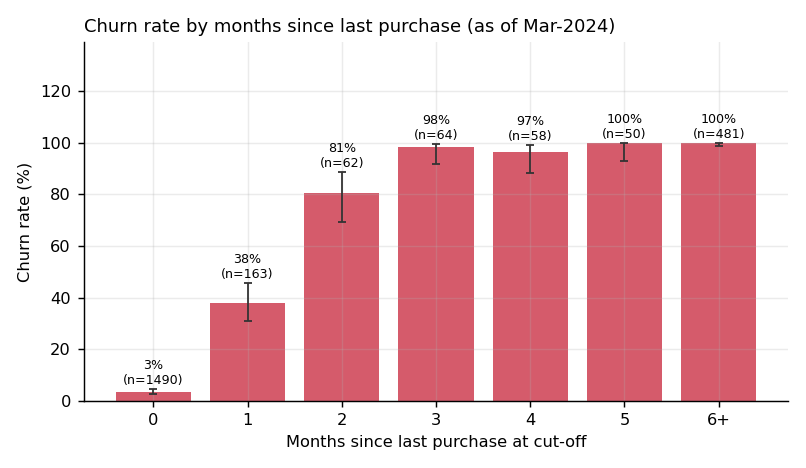

,rec,churned,members,churn_rate,ci_low,ci_high
0,0,52,1490,0.035,0.027,0.045
1,1,62,163,0.380,0.309,0.457
2,2,50,62,0.806,0.691,0.886
3,3,63,64,0.984,0.917,0.997
4,4,56,58,0.966,0.883,0.990
5,5,50,50,1.000,0.929,1.000
6,6+,480,481,0.998,0.988,1.000


In [6]:
display(Image(str(FIG / 'eda_02_recency.png')))
pd.read_csv(TAB / '02_churn_by_recency.csv').round(3)

### 2.3 Segments (tier, signup cohort, support tickets)
Across *all* eligible members, tickets look 'protective' only because lapsed members generate no tickets - the active-base view below removes that artefact.

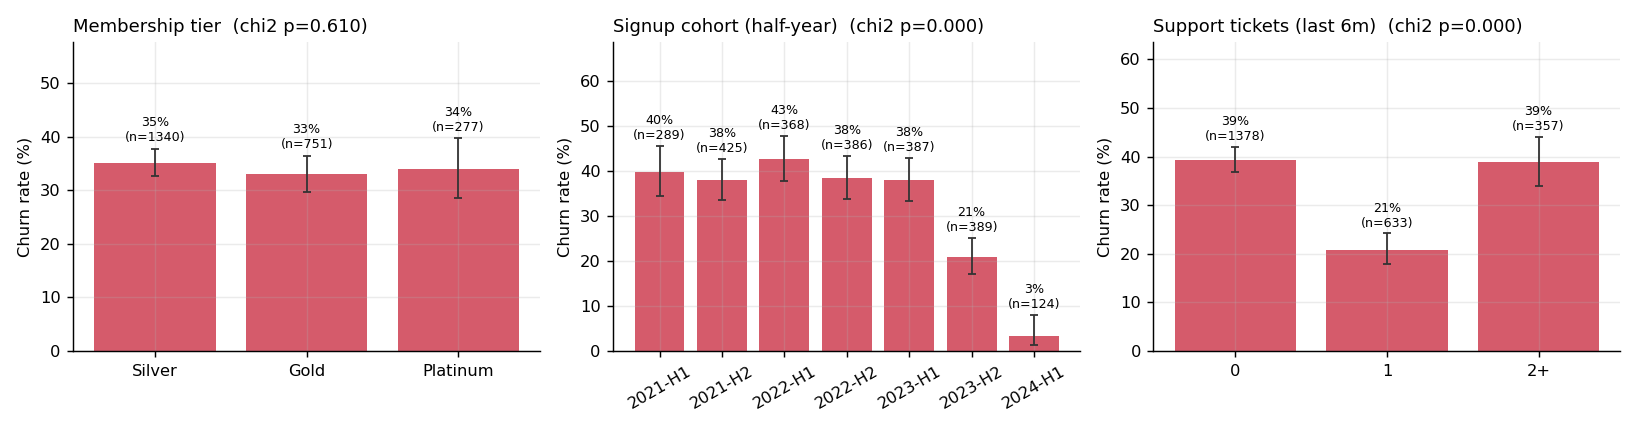

In [7]:
display(Image(str(FIG / 'eda_03_segments_all.png')))

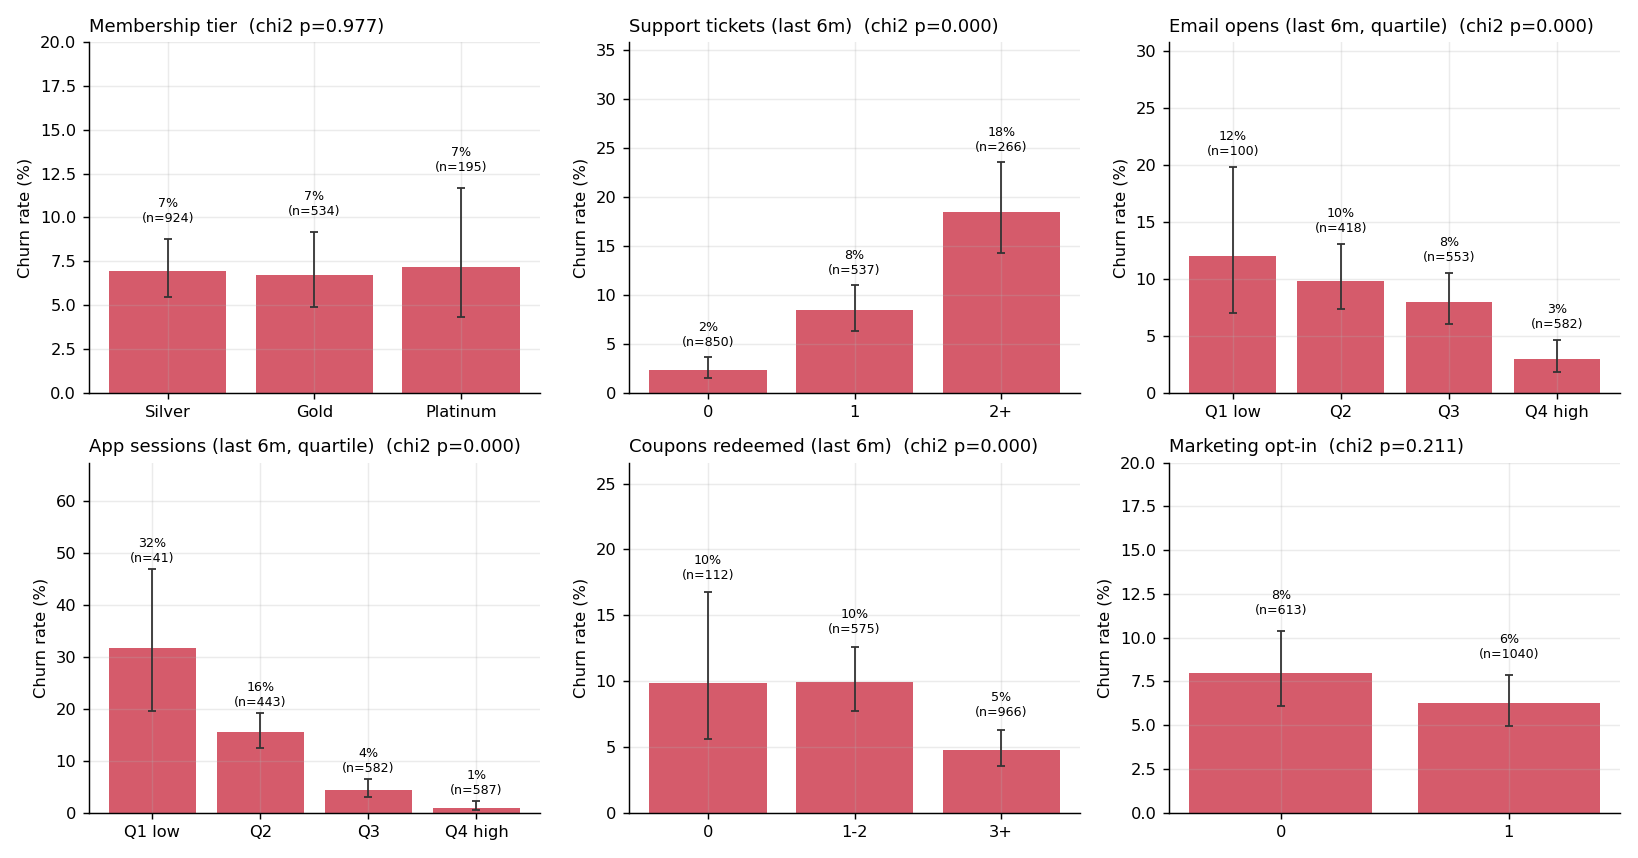

In [8]:
display(Image(str(FIG / 'eda_04_active_base_drivers.png')))

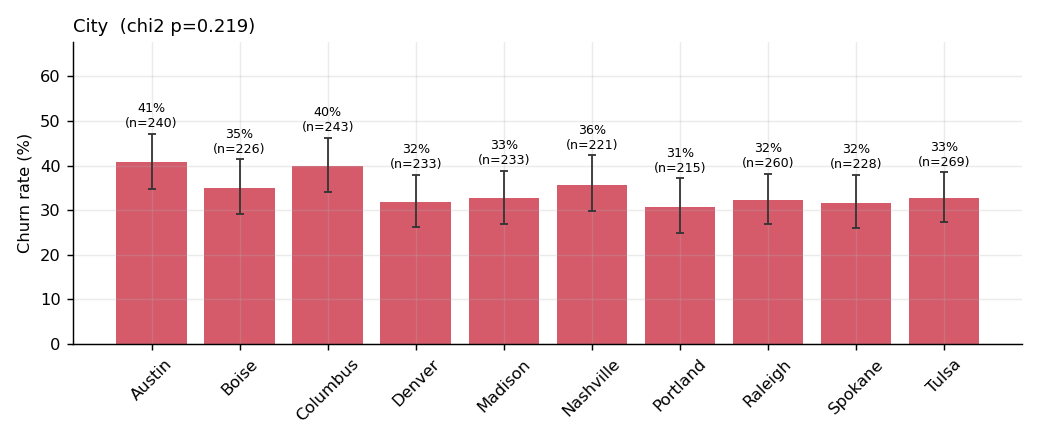

In [9]:
display(Image(str(FIG / 'eda_05_city.png')))

### 2.4 Behavioural trajectories before the label window

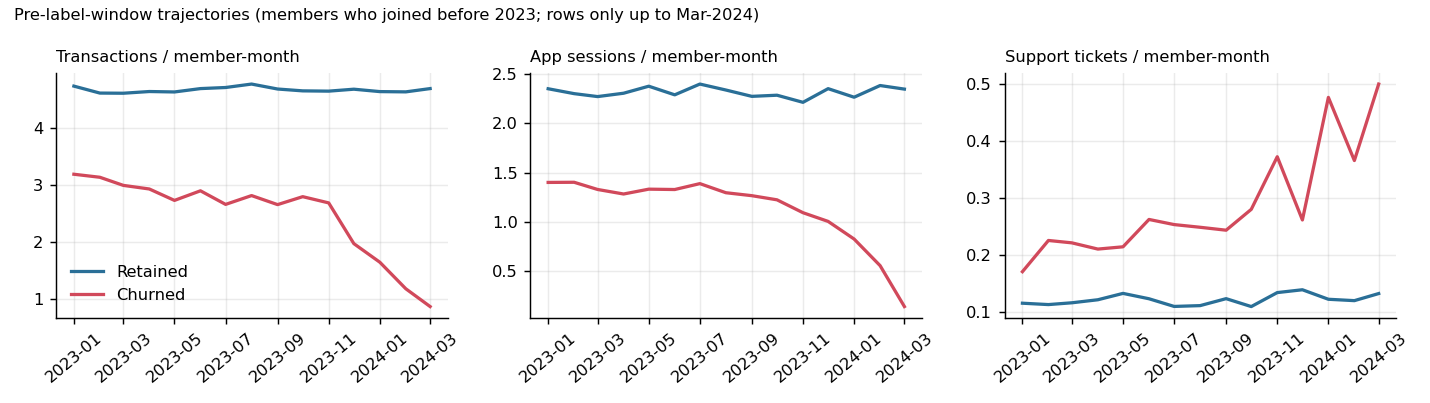

In [10]:
display(Image(str(FIG / 'eda_06_trajectories.png')))

### 2.5 Feature correlation / redundancy

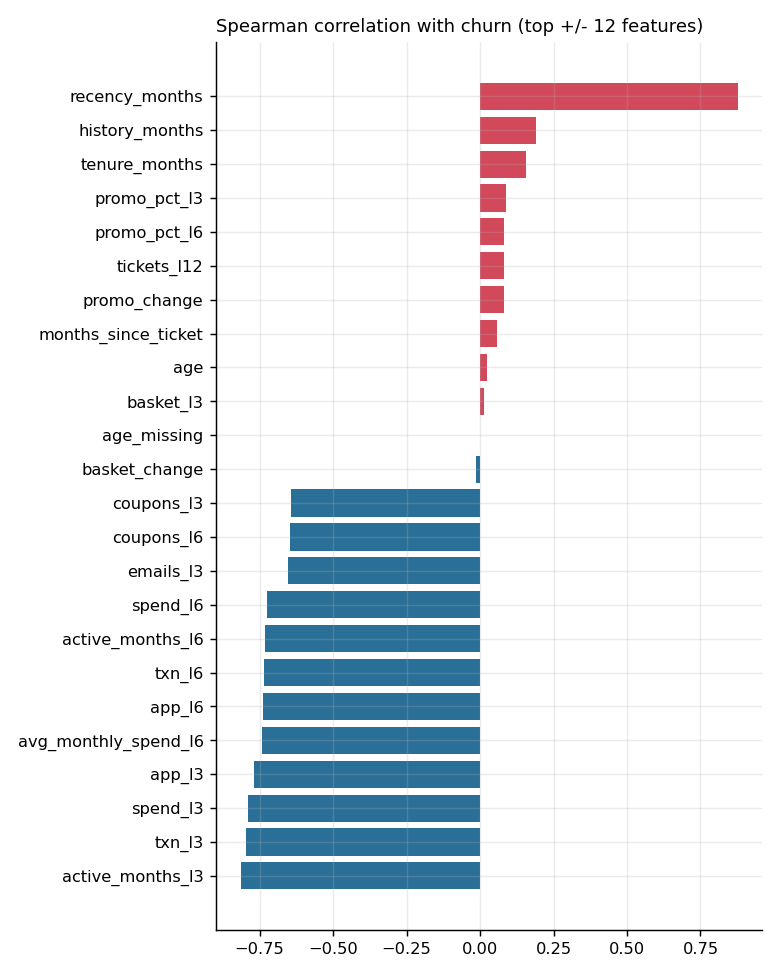

spend_l6            avg_monthly_spend_l6    0.985656
txn_ratio_l3_prev3  spend_ratio_l3_prev3    0.976776
txn_l3              spend_l3                0.968566
txn_l6              spend_l6                0.965104
txn_l12             spend_l12               0.963173
txn_slope_l6        spend_slope_l6          0.962545
spend_l3            avg_monthly_spend_l6    0.951282
txn_l6              avg_monthly_spend_l6    0.945885
app_l3              app_l6                  0.945673
spend_l3            spend_l6                0.935543
txn_l3              txn_l6                  0.929487
spend_l6            spend_l12               0.913209
Name: |spearman|, dtype: float64

In [11]:
display(Image(str(FIG / 'eda_07_feature_correlation.png')))
num = E.select_dtypes('number').drop(columns=['y','CHURNED','eligible','churn_derived'])
c = num.corr(method='spearman').abs().where(np.triu(np.ones((num.shape[1],)*2), 1).astype(bool)).stack()
c[c > 0.9].sort_values(ascending=False).head(12).rename('|spearman|')

Highly collinear window features (e.g. `txn_l6`/`txn_l12`) are kept: tree models are robust to them and the logistic baseline is L2-regularised.